<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/08_comparacion_temporal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08 — Comparación temporal: ¿cambia el desbalance modal con películas nuevas?

Se aplican **los modelos entrenados en el 06** (sin reentrenar) a las películas de TMDB del 07 y se
mide lo mismo en cada grupo: rendimiento por modalidad y diagnóstico del desbalance.

| Grupo | Películas | Fuente de póster y sinopsis | Embeddings de |
|---|---|---|---|
| `test_mmimdb` | todo el test de MM-IMDB | MM-IMDB | 03 (referencia del 06) |
| `control_mmimdb` | las películas control | MM-IMDB | 03 |
| `control_tmdb` | **las mismas** películas control | TMDB | 07 |
| `recientes_tmdb` | películas 2020–2026 | TMDB | 07 |

**Dos efectos, dos restas:**
- **Efecto de la fuente** = `control_tmdb − control_mmimdb`: mismas películas y etiquetas, solo cambia
  de dónde salen póster y sinopsis. Es **pareado** (película por película).
- **Efecto de la época** = `recientes_tmdb − control_tmdb`: misma fuente, distinta época. Es la
  respuesta a la pregunta del proyecto. Las muestras son **independientes**.

Todas las etiquetas son las de **IMDb hoy** y se evalúa en los géneros de comparación del 05
(restringidos a los que tienen suficientes positivos en cada grupo).

**Qué se mide en cada grupo** (mismas definiciones del 06):

| Medida | Qué dice |
|---|---|
| AP macro de imagen, texto y fusión | rendimiento por modalidad, sin depender de umbrales |
| Ganancia de la fusión sobre el texto | cuánto suma la imagen al combinarse |
| Índice de dependencia de la imagen | qué parte del trabajo de la fusión depende de la imagen (ablación) |
| Î(X_img; Y \| X_txt) calibrado | información nueva que aporta la imagen dado el texto (log-loss con temperatura del 06) |
| ECE | calibración de cada modelo fuera de su distribución de entrenamiento |

Corre en CPU en pocos minutos.

In [3]:
import os, sys, json, subprocess
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    try:
        drive.mount('/content/drive', force_remount=True)
    except Exception as e:
        print("Error al montar Google Drive. Asegúrate de dar los permisos necesarios en la ventana emergente de Colab.")
        print(f"Detalle del error: {e}")

REPO = '/content/Proyecto_Multimodal'
if os.path.exists(REPO):
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/AndresAvella09/Proyecto_Multimodal.git', REPO], check=True)
sys.path.insert(0, REPO)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src.datos import cargar, aplicar_estandarizacion
from src.modelos import cargar_artefactos, predecir_logits
from src.metricas import (sigmoide, f1_por_clase, ap_por_clase_rapido, ic95, bce_por_etiqueta, ece)

DATA = '/content/drive/MyDrive/proyecto_multimodal/data'
EMB = '/content/drive/MyDrive/proyecto_multimodal/embeddings'
RES = '/content/drive/MyDrive/proyecto_multimodal/results'

SEED, N_BOOT, MIN_POSITIVOS = 42, 1000, 10
device = 'cuda' if torch.cuda.is_available() else 'cpu'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
GRUPOS = ['test_mmimdb', 'control_mmimdb', 'control_tmdb', 'recientes_tmdb']
COL_GRUPO = {'test_mmimdb': '#94a3b8', 'control_mmimdb': '#2563eb', 'control_tmdb': '#10b981', 'recientes_tmdb': '#ea580c'}
COL_MOD = {'imagen': '#f59e0b', 'texto': '#2563eb', 'fusion_ingenua': '#10b981'}

Mounted at /content/drive


## 1. Modelos del 06 y los cuatro grupos

Los embeddings de TMDB se estandarizan con **la media y la desviación de train de MM-IMDB** guardadas
en el 06: es lo que vería el modelo en producción, y estandarizar con datos de TMDB borraría parte del
cambio de distribución que se quiere medir.

In [4]:
art = cargar_artefactos(f'{RES}/exp2_hoy_artefactos.pt', device)
assert art['etiquetas'] == 'hoy', "el 08 compara con etiquetas de IMDb hoy: correr el 06 con ETIQUETAS='hoy'"
MODELOS = art['modelos']
SEMILLAS = sorted({s for _, s in MODELOS})
G_ENT, G_EVAL = art['generos_entrenamiento'], art['generos_evaluacion']
print(f"{len(MODELOS)} modelos | semillas {SEMILLAS} | {len(G_EVAL)} géneros de evaluación")

# MM-IMDB (embeddings del 03, etiquetas de hoy)
X_mm, Y_mm, idx_mm, _, meta_mm = cargar(DATA, EMB, etiquetas='hoy')
Xz_mm = aplicar_estandarizacion(X_mm, art['stats_estandarizacion'])

# TMDB (embeddings del 07)
tm = pd.read_parquet(f'{DATA}/tmdb_meta.parquet')
X_tm = {'img': np.load(f'{EMB}/tmdb_clip_img.npy'), 'txt': np.load(f'{EMB}/tmdb_distilbert_txt.npy')}
assert all(len(v) == len(tm) for v in X_tm.values())
Xz_tm = aplicar_estandarizacion(X_tm, art['stats_estandarizacion'])
Y_tm = tm[[f'hoy_{g}' for g in G_ENT]].values.astype(np.float32)

i_ctrl = np.where(tm['grupo'] == 'control')[0]
i_rec = np.where(tm['grupo'] == 'reciente')[0]
filas_ctrl = tm['fila_hdf5'].values[i_ctrl]
assert np.isin(filas_ctrl, idx_mm['test']).all(), "el control debe salir del test de MM-IMDB"
assert (Y_mm[filas_ctrl] == Y_tm[i_ctrl]).all(), "las etiquetas del control deben coincidir en ambas fuentes"

grupos = {
    'test_mmimdb':    ({m: Xz_mm[m][idx_mm['test']] for m in Xz_mm}, Y_mm[idx_mm['test']]),
    'control_mmimdb': ({m: Xz_mm[m][filas_ctrl] for m in Xz_mm}, Y_mm[filas_ctrl]),
    'control_tmdb':   ({m: Xz_tm[m][i_ctrl] for m in Xz_tm}, Y_tm[i_ctrl]),
    'recientes_tmdb': ({m: Xz_tm[m][i_rec] for m in Xz_tm}, Y_tm[i_rec]),
}
for g, (x, y) in grupos.items():
    print(f"{g:15s} n={len(y):5d} | géneros por película {y.sum(1).mean():.2f}")

15 modelos | semillas [0, 1, 2, 3, 4] | 20 géneros de evaluación
test_mmimdb     n= 7784 | géneros por película 2.35
control_mmimdb  n= 1496 | géneros por película 2.34
control_tmdb    n= 1496 | géneros por película 2.34
recientes_tmdb  n= 2997 | géneros por película 2.55


### ¿Qué géneros se comparan? ¿Cambió la mezcla de géneros?

Un género entra si tiene al menos `MIN_POSITIVOS` películas en los tres grupos clave. Con menos, su AP
salta por azar.

La **prevalencia** importa: el AP de un género depende de qué tan frecuente es (un clasificador al azar
tiene AP = prevalencia). Si un género es más frecuente entre las recientes, su AP puede subir sin que el
modelo mejore. Por eso se muestra la mezcla de géneros de cada grupo antes de interpretar.

Géneros comparados: 20 de 20
Fuera por pocos positivos: []


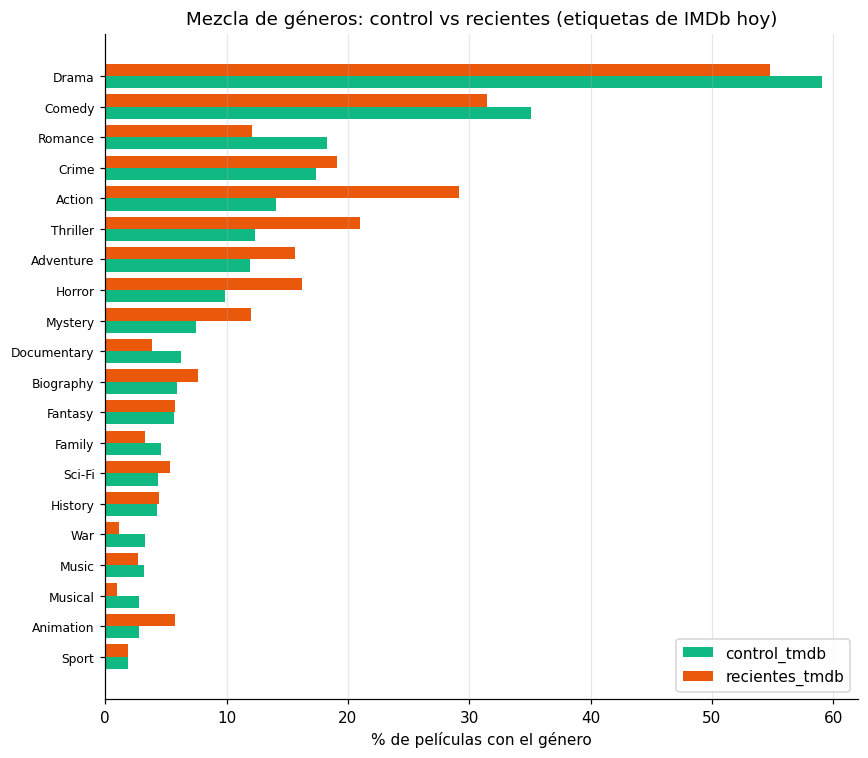

In [5]:
cols_eval = np.array([G_ENT.index(g) for g in G_EVAL])
pos = np.stack([grupos[g][1][:, cols_eval].sum(0) for g in ['control_mmimdb', 'recientes_tmdb']])
ok = (pos >= MIN_POSITIVOS).all(0)
GENEROS = [g for g, k in zip(G_EVAL, ok) if k]
COLS = np.array([G_ENT.index(g) for g in GENEROS])           # columnas de los 23 logits
UMB_COLS = np.array([G_EVAL.index(g) for g in GENEROS])      # columnas de los umbrales del 06
print(f"Géneros comparados: {len(GENEROS)} de {len(G_EVAL)}")
print("Fuera por pocos positivos:", [g for g, k in zip(G_EVAL, ok) if not k])

prev = pd.DataFrame({g: grupos[g][1][:, COLS].mean(0) for g in GRUPOS}, index=GENEROS)
prev = prev.sort_values('control_tmdb')
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(prev))
for k, g in enumerate(['control_tmdb', 'recientes_tmdb']):
    ax.barh(y + (k - 0.5) * 0.4, 100 * prev[g], height=0.4, color=COL_GRUPO[g], label=g)
ax.set_yticks(y, prev.index, fontsize=8); ax.grid(axis='y', visible=False)
ax.set_xlabel('% de películas con el género'); ax.legend(loc='lower right')
ax.set_title('Mezcla de géneros: control vs recientes (etiquetas de IMDb hoy)')
plt.tight_layout(); plt.show()

## 2. Predicciones

Para cada grupo y cada uno de los 15 modelos se guardan los logits. Para la fusión también con cada
rama **apagada** (vector cero = media de train), igual que la ablación del 06.

In [6]:
def a_tensor(x):
    return torch.from_numpy(x).to(device)

logits = {}   # (grupo, modelo, semilla) -> (n, C); modelos extra: 'sin_imagen', 'sin_texto'
for g, (x, _) in grupos.items():
    for (n, s), modelo in MODELOS.items():
        mods = art['modalidades'][n]
        logits[(g, n, s)] = predecir_logits(modelo, [a_tensor(x[m]) for m in mods])[:, COLS]
        if n == 'fusion_ingenua':
            for apagada, nombre in [('img', 'sin_imagen'), ('txt', 'sin_texto')]:
                xs = [torch.zeros_like(a_tensor(x[m])) if m == apagada else a_tensor(x[m]) for m in mods]
                logits[(g, nombre, s)] = predecir_logits(modelo, xs)[:, COLS]

TEMP = {(n, s): art['temperaturas'][f'{n}_s{s}'] for (n, s) in MODELOS}
print(f"{len(logits)} matrices de logits")

100 matrices de logits


## 3. Medidas por grupo (media ± IC 95% sobre semillas)

El F1 usa los **umbrales elegidos en dev de MM-IMDB** (06). Si la distribución cambia, esos umbrales
dejan de ser óptimos: es parte del costo real de usar el modelo en datos nuevos. Por eso la medida
principal para comparar grupos es el **AP**, que no depende de umbrales.

In [7]:
def medidas(Y, L):
    # Y: (n, C). L: logits por clave ('imagen', 'texto', 'fusion_ingenua', 'sin_imagen', 'sin_texto',
    # 'texto_cal', 'fusion_cal'). Devuelve las medidas del diagnóstico para un conjunto de películas.
    ap = {k: np.nanmean(ap_por_clase_rapido(Y, L[k]))
          for k in ['imagen', 'texto', 'fusion_ingenua', 'sin_imagen', 'sin_texto']}
    caida_i, caida_t = ap['fusion_ingenua'] - ap['sin_imagen'], ap['fusion_ingenua'] - ap['sin_texto']
    return {'ap_imagen': ap['imagen'], 'ap_texto': ap['texto'], 'ap_fusion': ap['fusion_ingenua'],
            'ganancia_fusion_sobre_texto': ap['fusion_ingenua'] - ap['texto'],
            'indice_dependencia_imagen': caida_i / (caida_i + caida_t),
            'cmi_img_dado_txt': (bce_por_etiqueta(Y, L['texto_cal']) - bce_por_etiqueta(Y, L['fusion_cal'])).sum(1).mean(),
            'ece_imagen': ece(Y, sigmoide(L['imagen'])), 'ece_texto': ece(Y, sigmoide(L['texto'])),
            'ece_fusion': ece(Y, sigmoide(L['fusion_ingenua']))}

def logits_semilla(g, s):
    L = {k: logits[(g, k, s)] for k in ['imagen', 'texto', 'fusion_ingenua', 'sin_imagen', 'sin_texto']}
    L['texto_cal'] = L['texto'] / TEMP[('texto', s)]
    L['fusion_cal'] = L['fusion_ingenua'] / TEMP[('fusion_ingenua', s)]
    return L

filas = []
for g in GRUPOS:
    Y = grupos[g][1][:, COLS]
    for s in SEMILLAS:
        L = logits_semilla(g, s)
        f1 = {f'f1_{n}': f1_por_clase(Y, (sigmoide(L[n]) >= art['umbrales'][f'{n}_s{s}'][UMB_COLS]).astype(np.float32)).mean()
              for n in ['imagen', 'texto', 'fusion_ingenua']}
        filas.append({'grupo': g, 'semilla': s, **medidas(Y, L), **f1})
por_semilla = pd.DataFrame(filas)

MEDIDAS = ['ap_imagen', 'ap_texto', 'ap_fusion', 'ganancia_fusion_sobre_texto', 'indice_dependencia_imagen',
           'cmi_img_dado_txt', 'ece_imagen', 'ece_texto', 'ece_fusion', 'f1_imagen', 'f1_texto', 'f1_fusion_ingenua']
tabla = por_semilla.groupby('grupo').agg(**{m: (m, lambda x: '{:.3f} ± {:.3f}'.format(*ic95(x))) for m in MEDIDAS})
tabla.loc[GRUPOS].T

grupo,test_mmimdb,control_mmimdb,control_tmdb,recientes_tmdb
ap_imagen,0.443 ± 0.001,0.425 ± 0.003,0.428 ± 0.005,0.431 ± 0.003
ap_texto,0.591 ± 0.002,0.577 ± 0.003,0.568 ± 0.004,0.529 ± 0.003
ap_fusion,0.638 ± 0.001,0.624 ± 0.001,0.626 ± 0.002,0.590 ± 0.001
ganancia_fusion_sobre_texto,0.046 ± 0.001,0.047 ± 0.004,0.058 ± 0.002,0.061 ± 0.003
indice_dependencia_imagen,0.200 ± 0.007,0.195 ± 0.014,0.222 ± 0.007,0.271 ± 0.006
cmi_img_dado_txt,0.289 ± 0.016,0.294 ± 0.018,0.324 ± 0.015,0.464 ± 0.047
ece_imagen,0.009 ± 0.002,0.010 ± 0.002,0.009 ± 0.001,0.016 ± 0.003
ece_texto,0.008 ± 0.001,0.011 ± 0.001,0.015 ± 0.002,0.020 ± 0.002
ece_fusion,0.007 ± 0.001,0.009 ± 0.001,0.012 ± 0.002,0.017 ± 0.003
f1_imagen,0.457 ± 0.002,0.439 ± 0.004,0.435 ± 0.005,0.437 ± 0.006


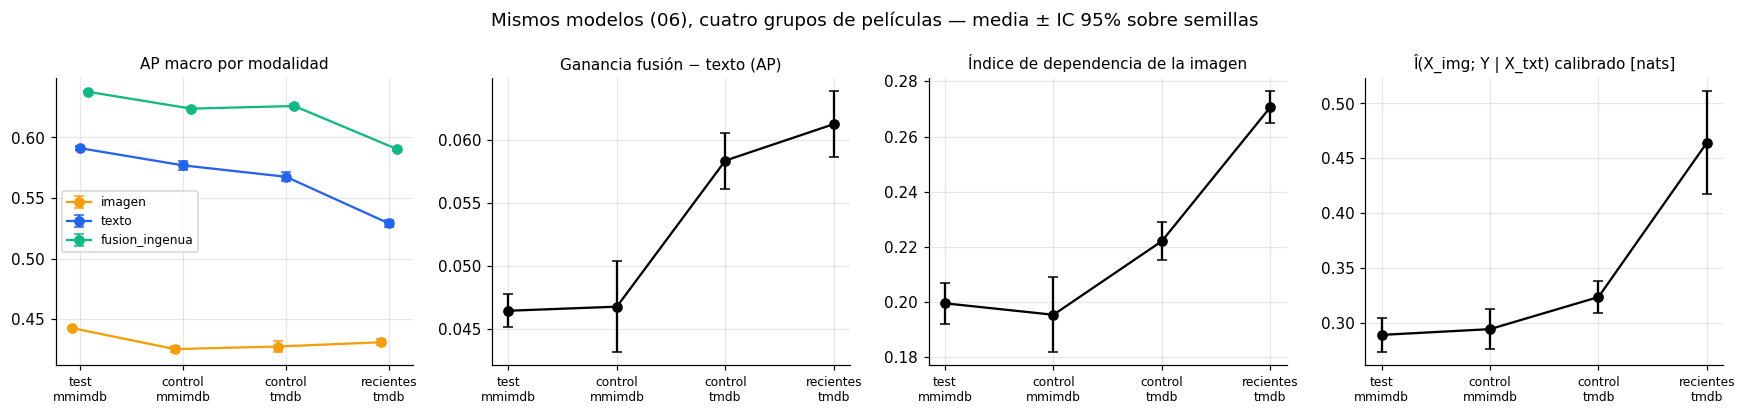

In [8]:
paneles = [('AP macro por modalidad', None), ('Ganancia fusión − texto (AP)', 'ganancia_fusion_sobre_texto'),
           ('Índice de dependencia de la imagen', 'indice_dependencia_imagen'),
           ('Î(X_img; Y | X_txt) calibrado [nats]', 'cmi_img_dado_txt')]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
x = np.arange(len(GRUPOS))
for ax, (titulo, col) in zip(axes, paneles):
    series = [('imagen', 'ap_imagen'), ('texto', 'ap_texto'), ('fusion_ingenua', 'ap_fusion')] if col is None else [(None, col)]
    for k, (n, c) in enumerate(series):
        m_h = [ic95(por_semilla[por_semilla['grupo'] == g][c]) for g in GRUPOS]
        ax.errorbar(x + 0.08 * (k - 1) * (col is None), [m for m, _ in m_h], yerr=[h for _, h in m_h],
                    marker='o', capsize=3, color=COL_MOD[n] if n else 'black', label=n)
    ax.set_xticks(x, [g.replace('_', '\n') for g in GRUPOS], fontsize=8); ax.set_title(titulo, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle('Mismos modelos (06), cuatro grupos de películas — media ± IC 95% sobre semillas')
plt.tight_layout(); plt.show()

## 4. Descomposición: efecto de la fuente y efecto de la época

Los IC sobre semillas solo reflejan la variabilidad del entrenamiento. Para comparar grupos importa más
la variabilidad **por muestra de películas**, que se estima con **bootstrap** sobre los logits promedio
de las 5 semillas:

- **Fuente** (`control_tmdb − control_mmimdb`): se re-muestrean películas control y se usa **el mismo
  re-muestreo** en las dos fuentes (pareado). Esto quita la variabilidad entre películas y deja solo la
  de la fuente.
- **Época** (`recientes_tmdb − control_tmdb`): se re-muestrea cada grupo por separado.

Un IC que no incluye 0 indica un efecto detectable con estos tamaños de muestra.

In [9]:
def logits_promedio(g):
    # Logits promediados sobre semillas (los calibrados: cada semilla con su temperatura)
    L = {k: np.mean([logits[(g, k, s)] for s in SEMILLAS], axis=0)
         for k in ['imagen', 'texto', 'fusion_ingenua', 'sin_imagen', 'sin_texto']}
    L['texto_cal'] = np.mean([logits[(g, 'texto', s)] / TEMP[('texto', s)] for s in SEMILLAS], axis=0)
    L['fusion_cal'] = np.mean([logits[(g, 'fusion_ingenua', s)] / TEMP[('fusion_ingenua', s)] for s in SEMILLAS], axis=0)
    return L

LP = {g: logits_promedio(g) for g in GRUPOS}
YG = {g: grupos[g][1][:, COLS] for g in GRUPOS}
def med(g, r=None):
    r = slice(None) if r is None else r
    return medidas(YG[g][r], {k: v[r] for k, v in LP[g].items()})

claves = list(med('control_tmdb').keys())
rng = np.random.default_rng(SEED)
n_c, n_r = len(YG['control_tmdb']), len(YG['recientes_tmdb'])
boot = {'fuente': [], 'epoca': []}
for _ in range(N_BOOT):
    rc = rng.integers(0, n_c, n_c)                               # mismo re-muestreo en ambas fuentes
    a, b = med('control_mmimdb', rc), med('control_tmdb', rc)
    boot['fuente'].append([b[k] - a[k] for k in claves])
    rr = rng.integers(0, n_r, n_r); rc2 = rng.integers(0, n_c, n_c)
    c, b2 = med('recientes_tmdb', rr), med('control_tmdb', rc2)
    boot['epoca'].append([c[k] - b2[k] for k in claves])

punto = {'fuente': {k: med('control_tmdb')[k] - med('control_mmimdb')[k] for k in claves},
         'epoca': {k: med('recientes_tmdb')[k] - med('control_tmdb')[k] for k in claves}}
filas = []
for efecto in ['fuente', 'epoca']:
    b = np.array(boot[efecto])
    for j, k in enumerate(claves):
        lo, hi = np.percentile(b[:, j], [2.5, 97.5])
        filas.append({'efecto': efecto, 'medida': k, 'diferencia': punto[efecto][k], 'ic_inf': lo, 'ic_sup': hi,
                      'detectable': not (lo <= 0 <= hi)})
descomp = pd.DataFrame(filas)
descomp.pivot(index='medida', columns='efecto', values='diferencia').loc[claves].round(4).join(
    descomp.assign(ic=lambda d: d.apply(lambda r: f"[{r.ic_inf:+.4f}, {r.ic_sup:+.4f}]{' *' if r.detectable else ''}", axis=1))
           .pivot(index='medida', columns='efecto', values='ic').add_prefix('IC_'))

efecto,epoca,fuente,IC_epoca,IC_fuente
medida,,,,
ap_imagen,0.0008,0.0035,"[-0.0266, +0.0249]","[-0.0154, +0.0221]"
ap_texto,-0.0405,-0.0078,"[-0.0688, -0.0111] *","[-0.0254, +0.0094]"
ap_fusion,-0.0367,0.0025,"[-0.0647, -0.0091] *","[-0.0142, +0.0186]"
ganancia_fusion_sobre_texto,0.0039,0.0103,"[-0.0115, +0.0177]","[-0.0030, +0.0249]"
indice_dependencia_imagen,0.0531,0.0233,"[+0.0062, +0.0962] *","[-0.0196, +0.0625]"
cmi_img_dado_txt,0.1393,0.0316,"[+0.0691, +0.2099] *","[-0.0210, +0.0832]"
ece_imagen,0.0071,-0.0009,"[+0.0036, +0.0097] *","[-0.0039, +0.0014]"
ece_texto,0.0046,0.0041,"[+0.0013, +0.0077] *","[+0.0018, +0.0068] *"
ece_fusion,0.0056,0.0019,"[+0.0021, +0.0077] *","[+0.0002, +0.0043] *"


**Cómo leer la tabla** (`*` = IC sin el 0):

- Si `ap_imagen` cae mucho más con la **época** que `ap_texto`, la rama visual envejece peor. Una
  explicación posible es que CLIP no vio esas películas al entrenarse (sus datos son anteriores a 2021).
- Si el **índice de dependencia** o **Î** cambian con la época, el desbalance modal **no es fijo**: depende
  de la población de películas, lo que importa para un método que pondere modalidades.
- Si el efecto de la **fuente** es grande, parte de cualquier diferencia con las recientes es por TMDB y
  no por la época: por eso el efecto de la época se mide contra el control de TMDB y no contra MM-IMDB.

## 5. ¿Qué modalidad pierde más con la época, género por género?

Caída de AP de cada modelo entre el control y las recientes (ambos TMDB), logits promedio de semillas.

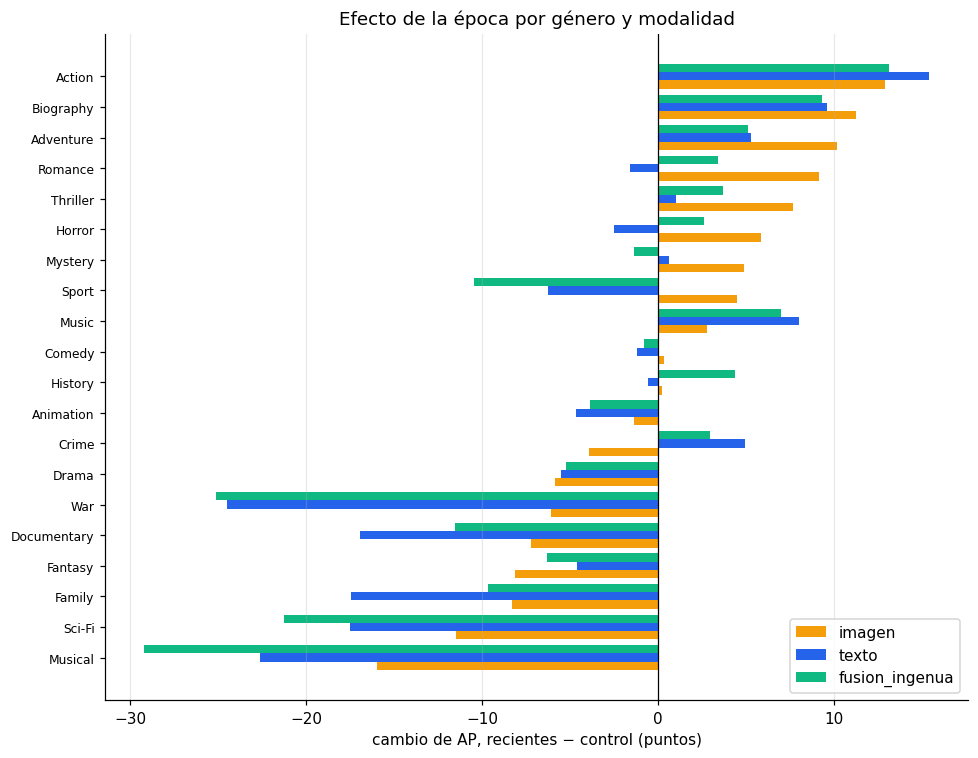

Correlación entre géneros: cambio de prevalencia vs cambio de AP de la fusión: r = 0.46


In [10]:
ap_g = {(g, n): ap_por_clase_rapido(YG[g], LP[g][n]) for g in ['control_tmdb', 'recientes_tmdb']
        for n in ['imagen', 'texto', 'fusion_ingenua']}
por_genero = pd.DataFrame({f'cambio_{n}': ap_g[('recientes_tmdb', n)] - ap_g[('control_tmdb', n)]
                           for n in ['imagen', 'texto', 'fusion_ingenua']}, index=GENEROS)
por_genero['cambio_prevalencia'] = YG['recientes_tmdb'].mean(0) - YG['control_tmdb'].mean(0)
por_genero = por_genero.sort_values('cambio_imagen')

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(por_genero))
for k, n in enumerate(['imagen', 'texto', 'fusion_ingenua']):
    ax.barh(y + (k - 1) * 0.27, 100 * por_genero[f'cambio_{n}'], height=0.27, color=COL_MOD[n], label=n)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y, por_genero.index, fontsize=8); ax.grid(axis='y', visible=False)
ax.set_xlabel('cambio de AP, recientes − control (puntos)'); ax.legend(loc='lower right')
ax.set_title('Efecto de la época por género y modalidad')
plt.tight_layout(); plt.show()
r = np.corrcoef(por_genero['cambio_prevalencia'], por_genero['cambio_fusion_ingenua'])[0, 1]
print(f"Correlación entre géneros: cambio de prevalencia vs cambio de AP de la fusión: r = {r:.2f}")

## 6. Robustez: popularidad

Las recientes del 05 son **más votadas** que el control (se eligieron las más votadas de cada año).
Si las películas populares son más fáciles, eso se mezcla con la época. Se comparan control y
recientes **dentro de los mismos tercios de votos** (cortes calculados con los dos grupos juntos).

En cada celda hay pocas películas por género, así que se usa el AP **micro** (todas las celdas
película×género juntas), que es estable con muestras chicas.

In [11]:
from sklearn.metrics import average_precision_score
votos = {'control_tmdb': tm['numVotes'].values[i_ctrl].astype(float),
         'recientes_tmdb': tm['numVotes'].values[i_rec].astype(float)}
cortes = np.nanpercentile(np.concatenate(list(votos.values())), [33.3, 66.7])
filas = []
for g in ['control_tmdb', 'recientes_tmdb']:
    tercio = np.digitize(votos[g], cortes)
    for t, nombre in enumerate(['bajo', 'medio', 'alto']):
        sel = tercio == t
        if sel.sum() < 30:
            continue
        fila = {'grupo': g, 'tercio_votos': nombre, 'n': int(sel.sum())}
        for n in ['imagen', 'texto', 'fusion_ingenua']:
            fila[f'ap_micro_{n}'] = average_precision_score(YG[g][sel].ravel(), LP[g][n][sel].ravel())
        filas.append(fila)
popularidad = pd.DataFrame(filas)
print(f"Cortes de votos: {cortes.round(0)}")
popularidad.pivot(index='tercio_votos', columns='grupo', values=['n', 'ap_micro_imagen', 'ap_micro_texto',
                                                                 'ap_micro_fusion_ingenua']).round(3)

Cortes de votos: [ 8866. 26282.]


n                ap_micro_imagen                 \
grupo        control_tmdb recientes_tmdb    control_tmdb recientes_tmdb   
tercio_votos                                                              
alto                332.0         1164.0           0.689          0.653   
bajo                924.0          572.0           0.590          0.584   
medio               240.0         1261.0           0.649          0.641   

             ap_micro_texto                ap_micro_fusion_ingenua  \
grupo          control_tmdb recientes_tmdb            control_tmdb   
tercio_votos                                                         
alto                  0.696          0.668                   0.767   
bajo                  0.687          0.646                   0.727   
medio                 0.725          0.680                   0.775   

                             
grupo        recientes_tmdb  
tercio_votos                 
alto                  0.741  
bajo                  0.707  
medio                 0.742

## Guardado

- `exp3_por_semilla.csv`: medidas de cada grupo y semilla.
- `exp3_descomposicion.csv`: efectos de fuente y época con IC bootstrap.
- `exp3_por_genero.csv`, `exp3_popularidad.csv`, `exp3_prevalencias.csv`.

In [12]:
por_semilla.to_csv(f'{RES}/exp3_por_semilla.csv', index=False)
descomp.to_csv(f'{RES}/exp3_descomposicion.csv', index=False)
por_genero.to_csv(f'{RES}/exp3_por_genero.csv')
popularidad.to_csv(f'{RES}/exp3_popularidad.csv', index=False)
prev.to_csv(f'{RES}/exp3_prevalencias.csv')
with open(f'{RES}/exp3_config.json', 'w') as fh:
    json.dump({'generos_comparados': GENEROS, 'min_positivos': MIN_POSITIVOS, 'n_bootstrap': N_BOOT,
               'semillas': SEMILLAS, 'n_por_grupo': {g: int(len(YG[g])) for g in GRUPOS}}, fh, indent=2)
print(sorted(f for f in os.listdir(RES) if f.startswith('exp3')))

['exp3_config.json', 'exp3_descomposicion.csv', 'exp3_popularidad.csv', 'exp3_por_genero.csv', 'exp3_por_semilla.csv', 'exp3_prevalencias.csv']
